In [1]:
import pandas as pd, numpy as np
COLS = ["unit","cycle","op1","op2","op3"] + [f"s{i}" for i in range(1,22)]
train = pd.read_csv("../data/raw/train_FD002.txt", sep=r"\s+", header=None, names=COLS)
test  = pd.read_csv("../data/raw/test_FD002.txt",  sep=r"\s+", header=None, names=COLS)

for name, df in [("train", train), ("test", test)]:
    lens = df.groupby("unit")["cycle"].max()
    print(name, df.shape, "| engines:", df.unit.nunique(), "| NaNs:", int(df.isna().sum().sum()),
          "| engine length min/mean/max:", lens.min(), round(lens.mean(), 1), lens.max())

ops = train[["op1","op2","op3"]].round({"op1": 0, "op2": 1, "op3": 0})
print(ops.value_counts())          # expect about 6 groups

train (53759, 26) | engines: 260 | NaNs: 0 | engine length min/mean/max: 128 206.8 378
test (33991, 26) | engines: 259 | NaNs: 0 | engine length min/mean/max: 21 131.2 367
op1   op2  op3  
42.0  0.8  100.0    13458
20.0  0.7  100.0     8122
0.0   0.0  100.0     8044
35.0  0.8  100.0     8037
25.0  0.6  60.0      8002
10.0  0.2  100.0     4138
      0.3  100.0     3958
Name: count, dtype: int64


In [2]:
def cond_id(df):
    s = df[["op1","op2","op3"]].round({"op1": 0, "op2": 2, "op3": 0}).astype(str)
    return s.agg("_".join, axis=1)

train["cond"] = cond_id(train)
test["cond"]  = cond_id(test)

print(train["cond"].value_counts())
print("conditions:", train["cond"].nunique())
print("test conditions missing from train:", set(test["cond"]) - set(train["cond"]))

cond
42.0_0.84_100.0    13458
20.0_0.7_100.0      8122
10.0_0.25_100.0     8096
0.0_0.0_100.0       8044
35.0_0.84_100.0     8037
25.0_0.62_60.0      8002
Name: count, dtype: int64
conditions: 6
test conditions missing from train: set()


In [3]:
# 4. RUL labels (cap 125)
last = train.groupby("unit")["cycle"].transform("max")
train["rul"] = (last - train["cycle"]).clip(upper=125)
print(train[train.unit == 1][["cycle", "rul"]].iloc[[0, 1, -2, -1]])
print("max RUL:", train["rul"].max(), "| min RUL:", train["rul"].min())

# 5. split by engine (80/20)
units = train["unit"].unique()
val_units = units[int(0.8 * len(units)):]
tr = train[~train.unit.isin(val_units)].copy()
va = train[train.unit.isin(val_units)].copy()
print("train engines:", tr.unit.nunique(), "| val engines:", va.unit.nunique())
print("overlap:", set(tr.unit) & set(va.unit))

     cycle  rul
0        1  125
1        2  125
147    148    1
148    149    0
max RUL: 125 | min RUL: 0
train engines: 208 | val engines: 52
overlap: set()


In [4]:
sensors = [f"s{i}" for i in range(1, 22)]
KEEP = ["s2","s3","s4","s7","s8","s9","s11","s12","s13","s14","s15","s17","s20","s21"]

# per-condition min/max from the 208 TRAIN engines only
lo = tr.groupby("cond")[sensors].min()
hi = tr.groupby("cond")[sensors].max()

def scale_cond(df):
    df = df.copy()
    lo_r = lo.loc[df["cond"]].to_numpy()
    hi_r = hi.loc[df["cond"]].to_numpy()
    rng = np.where(hi_r - lo_r == 0, 1.0, hi_r - lo_r)     # constant sensors -> avoid /0
    df[sensors] = 2 * (df[sensors].to_numpy() - lo_r) / rng - 1
    return df

tr_s, va_s = scale_cond(tr), scale_cond(va)

print("train range:", tr_s[sensors].min().min(), tr_s[sensors].max().max())
print("val range:  ", round(va_s[sensors].min().min(), 3), round(va_s[sensors].max().max(), 3))

std = tr_s[sensors].std().round(3)
print(std.to_string())
print("near-constant after scaling:", [s for s in sensors if std[s] < 0.05])
print("any KEEP sensor near-constant?", [s for s in KEEP if std[s] < 0.05])

train range: -1.0 1.0
val range:   -1.162 1.222
s1     0.000
s2     0.296
s3     0.282
s4     0.319
s5     0.000
s6     0.881
s7     0.278
s8     0.298
s9     0.200
s10    0.990
s11    0.325
s12    0.300
s13    0.306
s14    0.199
s15    0.305
s16    0.352
s17    0.294
s18    0.000
s19    0.000
s20    0.290
s21    0.283
near-constant after scaling: ['s1', 's5', 's18', 's19']
any KEEP sensor near-constant? []


In [5]:
print(tr.groupby("cond")[["s6","s10","s16"]].nunique())   # few unique values = quantized

corr = tr_s[sensors].corrwith(tr_s["rul"]).abs().sort_values(ascending=False).round(3)
print(corr.to_string())

                 s6  s10  s16
cond                         
0.0_0.0_100.0     2    1    1
10.0_0.25_100.0   2    2    1
20.0_0.7_100.0    3    2    2
25.0_0.62_60.0    3    2    1
35.0_0.84_100.0   2    2    1
42.0_0.84_100.0   2    2    1
s11    0.768
s15    0.723
s4     0.723
s17    0.645
s2     0.623
s3     0.611
s12    0.535
s7     0.512
s20    0.482
s21    0.477
s8     0.420
s9     0.414
s13    0.391
s14    0.309
s6     0.280
s16    0.237
s10    0.043
s1       NaN
s5       NaN
s18      NaN
s19      NaN


In [7]:
L = 30

def windows(df, L=L):
    X, y = [], []
    for _, g in df.groupby("unit"):
        a = g[KEEP].to_numpy(np.float32); r = g["rul"].to_numpy(np.float32)
        for i in range(len(a) - L + 1):
            X.append(a[i:i+L]); y.append(r[i+L-1])
    return np.stack(X), np.array(y)

Xtr, ytr = windows(tr_s)
Xva, yva = windows(va_s)

# test: last 30 cycles per engine, padded at the front if shorter
test_s = scale_cond(test)                       # uses the TRAIN per-condition lo/hi
def last_window(g):
    a = g[KEEP].to_numpy(np.float32)
    if len(a) < L:
        a = np.vstack([np.repeat(a[:1], L - len(a), 0), a])
    return a[-L:]
Xte = np.stack([last_window(g) for _, g in test_s.groupby("unit")])
yte = np.minimum(pd.read_csv("../data/raw/RUL_FD002.txt", header=None)[0].to_numpy(), 125).astype(np.float32)

print("train:", Xtr.shape, "| val:", Xva.shape, "| test:", Xte.shape, yte.shape)
print("train+val windows:", len(Xtr) + len(Xva), "(expect 46219)")
print("test engines shorter than 30:", int((test.groupby('unit')['cycle'].max() < L).sum()))

np.savez("../data/processed/processed_FD002.npz", Xtr=Xtr, ytr=ytr, Xva=Xva, yva=yva, Xte=Xte, yte=yte,
         lo=lo[KEEP].to_numpy(), hi=hi[KEEP].to_numpy(), conds=np.array(lo.index))

train: (37071, 30, 14) | val: (9148, 30, 14) | test: (259, 30, 14) (259,)
train+val windows: 46219 (expect 46219)
test engines shorter than 30: 6


In [8]:
import sys; sys.path.append("../src")
from train import train
ema, hist = train(npz="../data/processed/processed_FD002.npz", epochs=3,
                  save="../results/dit_fd002.pt")

epoch   1 | train 0.2711 | val (EMA) 0.0760
epoch   2 | train 0.0762 | val (EMA) 0.0725
epoch   3 | train 0.0725 | val (EMA) 0.0710
saved ../results/dit_fd002.pt


epoch   1 | train 0.2665 | val (EMA) 0.0751
epoch   2 | train 0.0756 | val (EMA) 0.0721
epoch   3 | train 0.0736 | val (EMA) 0.0709
epoch   4 | train 0.0723 | val (EMA) 0.0702
epoch   5 | train 0.0720 | val (EMA) 0.0697
epoch   6 | train 0.0718 | val (EMA) 0.0695
epoch   7 | train 0.0713 | val (EMA) 0.0692
epoch   8 | train 0.0727 | val (EMA) 0.0690
epoch   9 | train 0.0698 | val (EMA) 0.0688
epoch  10 | train 0.0709 | val (EMA) 0.0686
epoch  11 | train 0.0714 | val (EMA) 0.0685
epoch  12 | train 0.0707 | val (EMA) 0.0684
epoch  13 | train 0.0710 | val (EMA) 0.0683
epoch  14 | train 0.0706 | val (EMA) 0.0682
epoch  15 | train 0.0690 | val (EMA) 0.0681
epoch  16 | train 0.0701 | val (EMA) 0.0681
epoch  17 | train 0.0687 | val (EMA) 0.0680
epoch  18 | train 0.0689 | val (EMA) 0.0680
epoch  19 | train 0.0704 | val (EMA) 0.0679
epoch  20 | train 0.0701 | val (EMA) 0.0679
epoch  21 | train 0.0698 | val (EMA) 0.0678
epoch  22 | train 0.0706 | val (EMA) 0.0678
epoch  23 | train 0.0688 | val (

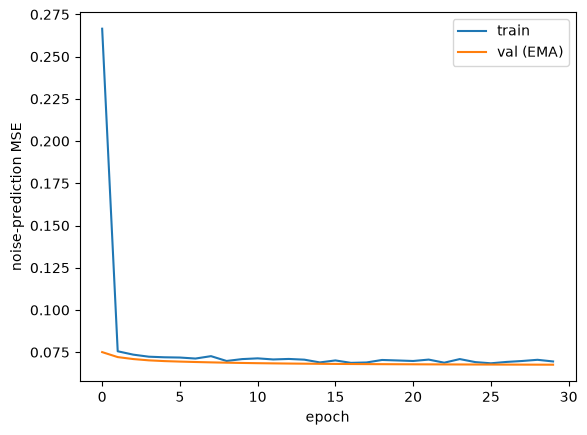

In [9]:
ema, hist = train(npz="../data/processed/processed_FD002.npz", epochs=30,
                  save="../results/dit_fd002.pt")

import matplotlib.pyplot as plt
tr, va = zip(*hist)
plt.plot(tr, label="train"); plt.plot(va, label="val (EMA)")
plt.xlabel("epoch"); plt.ylabel("noise-prediction MSE"); plt.legend()
plt.savefig("../results/loss_curve_fd002.png", dpi=150); plt.show()